# 06 — Explicabilité : comprendre les décisions du modèle avec SHAP

L'importance des variables (notebook 05) dit **quelles** variables comptent. Elle ne dit pas **dans quel sens** elles jouent, ni **pourquoi** le modèle a estimé tel prix pour tel logement.

**SHAP** (*SHapley Additive exPlanations*) répond à ces questions. Pour chaque estimation, il répartit l'écart entre le prix prédit et le prix moyen entre les différentes variables. Par exemple : « +18 % parce que le bien est à 500 m de la mer, −9 % parce qu'il est au fond de l'arrière-pays… ».

Comme le modèle prédit le **log du prix**, une contribution SHAP de +0,10 correspond à un effet d'environ **+10,5 %** sur le prix (exp(0,10) − 1).

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from pathlib import Path

racine = Path.cwd()
while not (racine / "data" / "raw").exists() and racine != racine.parent:
    racine = racine.parent

chemin_modele = racine / "models" / "lightgbm.joblib"
if not chemin_modele.exists():
    raise FileNotFoundError(f"Modèle introuvable : {chemin_modele}\n→ Lance d'abord le notebook 05_modelisation jusqu'au bout.")

sauvegarde = joblib.load(chemin_modele)
modele, FEATURES = sauvegarde["modele"], sauvegarde["features"]

donnees = pd.read_parquet(racine / "data" / "processed" / "features.parquet")
test = donnees[donnees["jeu"] == "test"]
dossier_fig = racine / "figures"

# SHAP sur 3 000 ventes de 2025 : largement suffisant pour les graphiques, et rapide
echantillon = test.sample(min(3000, len(test)), random_state=42)
X = echantillon[FEATURES]

explainer = shap.TreeExplainer(modele)
valeurs_shap = explainer(X)
print(f"Valeur de base (log du prix moyen prédit) : {valeurs_shap.base_values[0]:.2f}"
      f" → {np.exp(valeurs_shap.base_values[0]):,.0f} €")

Valeur de base (log du prix moyen prédit) : 12.31 → 221,614 €


## 1. Vue d'ensemble : quelles variables poussent le prix vers le haut ou vers le bas ?

Chaque point est une vente. Sa position horizontale indique l'effet de la variable sur le prix prédit (à droite : prix plus élevé), et sa couleur la valeur de la variable (rouge : valeur élevée, bleu : valeur faible).

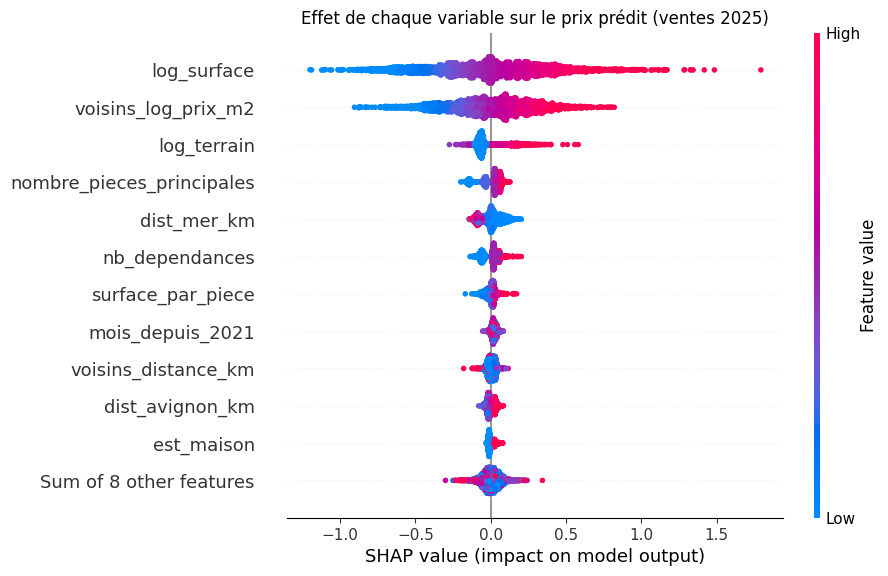

In [2]:
shap.plots.beeswarm(valeurs_shap, max_display=12, show=False)
plt.title("Effet de chaque variable sur le prix prédit (ventes 2025)")
plt.gcf().savefig(dossier_fig / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Zoom sur trois variables clés

Ces graphiques montrent comment l'effet d'une variable évolue selon sa valeur.

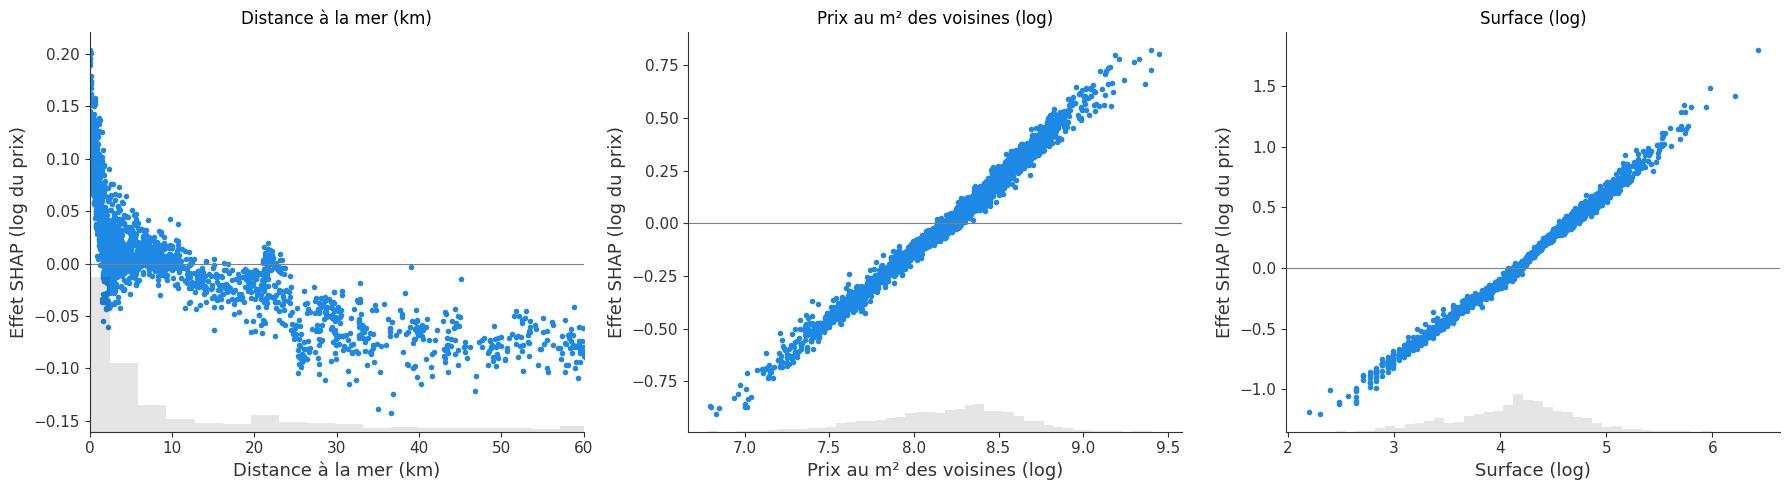

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, variable, titre in [
    (axes[0], "dist_mer_km", "Distance à la mer (km)"),
    (axes[1], "voisins_log_prix_m2", "Prix au m² des voisines (log)"),
    (axes[2], "log_surface", "Surface (log)"),
]:
    shap.plots.scatter(valeurs_shap[:, variable], ax=ax, show=False)
    ax.set(title=titre, xlabel=titre, ylabel="Effet SHAP (log du prix)")
    ax.axhline(0, color="grey", linewidth=0.8)
axes[0].set_xlim(0, 60)
fig.tight_layout()
fig.savefig(dossier_fig / "shap_dependances.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Expliquer une estimation précise

On prend deux ventes de 2025 : un appartement en bord de mer et une maison dans l'arrière-pays. Le graphique « en cascade » (*waterfall*) part du prix moyen prédit et montre, variable par variable, comment on arrive à l'estimation finale.

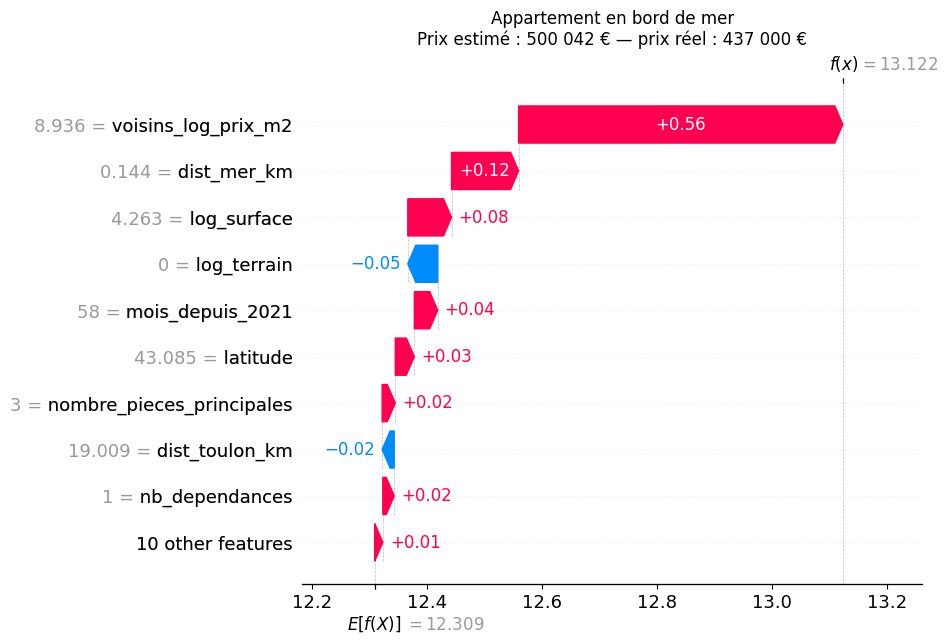

nom_commune                 Hyères
type_local             Appartement
surface_reelle_bati           71.0
dist_mer_km               0.143797
valeur_fonciere           437000.0
Name: 2025-1088180, dtype: object

In [4]:
def expliquer(position, titre, fichier):
    vente = echantillon.iloc[position]
    plt.figure()
    shap.plots.waterfall(valeurs_shap[position], max_display=10, show=False)
    plt.title(f"{titre}\nPrix estimé : {np.exp(modele.predict(X.iloc[[position]])[0]):,.0f} € — "
              f"prix réel : {vente['valeur_fonciere']:,.0f} €".replace(",", " "))
    plt.gcf().savefig(dossier_fig / fichier, dpi=150, bbox_inches="tight")
    plt.show()
    return vente[["nom_commune", "type_local", "surface_reelle_bati", "dist_mer_km", "valeur_fonciere"]]


positions = np.arange(len(echantillon))
bord_de_mer = positions[(echantillon["type_local"] == "Appartement").to_numpy() & (echantillon["dist_mer_km"] < 1).to_numpy()]
arriere_pays = positions[(echantillon["type_local"] == "Maison").to_numpy() & (echantillon["dist_mer_km"] > 50).to_numpy()]

if len(bord_de_mer):
    display(expliquer(bord_de_mer[0], "Appartement en bord de mer", "shap_exemple_bord_de_mer.png"))

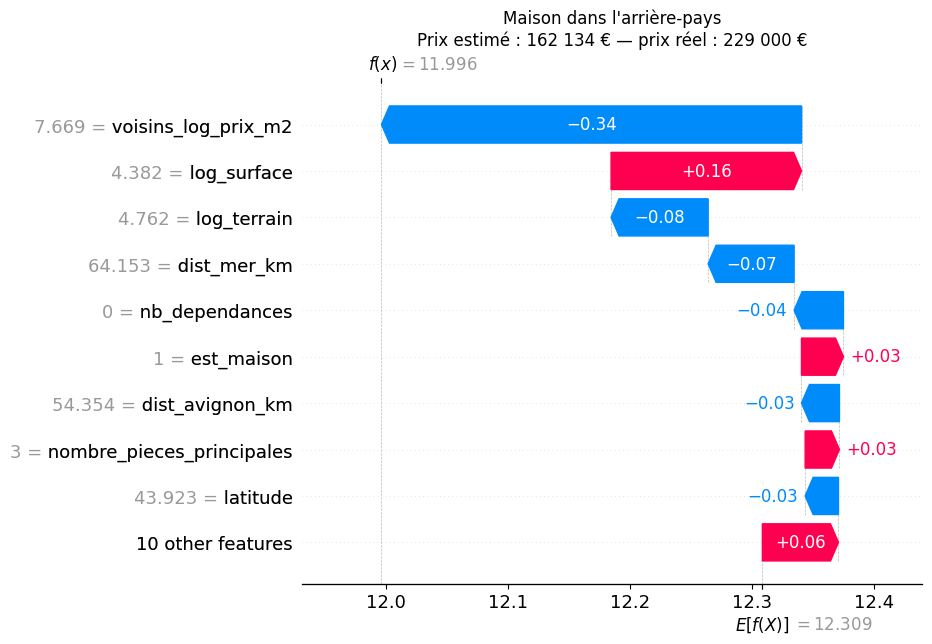

nom_commune              Rustrel
type_local                Maison
surface_reelle_bati         80.0
dist_mer_km            64.152989
valeur_fonciere         229000.0
Name: 2025-1099872, dtype: object

In [5]:
if len(arriere_pays):
    display(expliquer(arriere_pays[0], "Maison dans l'arrière-pays", "shap_exemple_arriere_pays.png"))

## 4. Ce que SHAP apporte

- **Vérifier que le modèle est cohérent** : on s'attend à ce que le prix augmente avec la surface et le prix du quartier, et baisse quand on s'éloigne de la mer. Si SHAP montrait l'inverse, ce serait le signe d'un problème (fuite de données, variable mal construite…).
- **Expliquer une estimation à un utilisateur** : c'est ce que fait l'application Streamlit du projet, qui affiche pour chaque estimation les facteurs qui font monter ou baisser le prix.